<a href="https://colab.research.google.com/github/sugarfreecat/festival-musica/blob/main/notebooks/01_analise_exploratoria_vendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔎Análise Exploratória de Vendas Aplicada com Python

## ❓Pergunta de Negócio

**Quais gêneros musicais e tipos de ingresso têm maior volume de vendas e faturamento?**

Colunas de análise: genero_musical (dimensão), valor (fato) e tipo_ingresso (fato)

Decisões que o resultado apoiaria: direcionar a programação de eventos e os investimentos para os gêneros musicais mais populares entre o público; alocar disponibilidade de ingressos para os tipos mais populares entre o público; direcionar campanhas de marketing para os tipos de ingressos que mais geram receita.

## 1️⃣ Preparando o Ambiente

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

## 2️⃣ Carregando os Arquivos CSV

O que esta célula faz: conecta o Google Drive, guarda os CSV na pasta Colab Notebooks/desafios/dados e lê os dois arquivos em DataFrames: df_dimensao e df_fato. Os nomes das tabelas são os mesmos dos arquivos, sem o .csv.

Na primeira execução, o Colab pede autorização para acessar o Drive.
Se algum arquivo ainda não estiver na pasta, abre a janela de seleção: escolha os 2 CSV de uma vez. O código identifica cada um pelo nome (o nome do arquivo precisa conter o nome da tabela) e salva já com o nome certo.
Nas próximas execuções, lê direto do Drive, sem pedir envio.

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)
print("-----------")
print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
-----------
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


## 3️⃣ Conhecendo a Tabela Dimensão

Lembrete: A tabela dimensão é aquela que descreve as coisas de um tema, onde cada linha é um item único e as colunas descrevem suas propriedades.

Neste caso, a tabela dimensão é a de atrações, que descreve todos os festivais disponíveis na base de dados

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


## 4️⃣ Conhecendo a Tabela Fato

Lembrete: A tabela fato lista ocorrências de eventos relacionados aos itens únicos da tabela dimensão.

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


## 5️⃣ Verificando Os Datasets

### Tipos dos Dados

In [5]:
display(df_fato.dtypes)
display(df_dimensao.dtypes)

,0
venda_id,int64
atracao_id,int64
tipo_ingresso,object
canal_venda,object
data_hora_venda,object
valor,float64
forma_pagamento,object


,0
atracao_id,int64
nome_artista,object
genero_musical,object
edicao_festival,object
dia_apresentacao,object
palco,object
horario_inicio,object


### Valores Ausentes

In [6]:
print("Valores ausentes por coluna na tabela fato:")
print(df_fato.isna().sum())

print("\nValores ausentes por coluna na tabela dimensão:")
print(df_dimensao.isna().sum())

Valores ausentes por coluna na tabela fato:
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64

Valores ausentes por coluna na tabela dimensão:
atracao_id          0
nome_artista        0
genero_musical      0
edicao_festival     0
dia_apresentacao    0
palco               0
horario_inicio      0
dtype: int64


### Linhas Duplicadas

In [8]:
print("Linhas duplicadas na tabela fato:", df_fato.duplicated().sum())
print("Linhas duplicadas na tabela dimensão:", df_dimensao.duplicated().sum())

Linhas duplicadas na tabela fato: 0
Linhas duplicadas na tabela dimensão: 0


### Chave Estrangeira
Todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.

In [9]:
COLUNA_FK = "atracao_id"        # coluna da fato que referencia a dimensão
COLUNA_ID = "atracao_id"   # coluna de ID da dimensão

# checa se FK de cada linha da tabela fato existe como PK na tabela dimensão
print("\nTodas as chaves estrangeiras batem?", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Todas as chaves estrangeiras batem? True


### Leitura da Conferência
- A tabela fato tem 9 colunas e 0 linhas duplicadas, enquanto a dimensão tem 7 colunas e 0 linhas duplicadas
- As chaves estrangeiras de todas as linhas da tabela fato batem com as chaves primárias da tabela dimensão
- Nenhuma das tabelas apresenta valores ausentes em suas colunas

## 6️⃣ Análise da Coluna Numérica (Valor)

### Checando a Coluna Numérica

In [11]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Medidas Estatísticas

In [12]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


### Insights
- **A média de valor é 469.54**. Isso significa que o valor médio dos ingressos vendidos foi 469,54 reais.

- **A mediana de valor é 290**. Isso significa que metade dos ingressos vendidos custaram até 290 reais, valor muito abaixo da média.

- **O desvio padrão de valor é 455.12**. Seu valor alto mostra que os valores são heterogêneos; ou seja, eles variam muito entre si.

- **Decisão final:** A média, mediana e o desvio padrão indicam que os preços entre os ingressos vendidos variam consideravelmente. Assim, essas medidas apoiam a decisão de segmentar as campanhas de marketing de acordo com as faixas de preço dos ingressos, os tipos de ingresso, e os diferentes públicos e suas disposições.

### Conclusões Finais
- A decisão final indica a necessidade de duas análises adicionais: valor médio de venda de diferentes tipos de ingressos, e gêneros mais populares entre diferentes tipos de ingressos.
- Essas duas análises adicionais poderão, no futuro, apoiar a análise principal da decisão final (com dados indisponíveis atualmente): como direcionar as campanhas de marketing (de acordo com tipos de ingresso, faixas de preço e gênero musical) para os públicos mais passíveis de conversão?

## 7️⃣ Ampliando a Análise: Comparando Grupos

Objetivo: comparar a mesma coluna númerica "valor" entre categorias (tipo de ingresso e gênero musical)

### Juntando as Duas Tabelas
A tabela completa continuará listando todas as vendas de ingressos da tabela fato, porém com o adicional de informações vindas da tabela dimensão.

In [13]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais
df_completo.head()

Linhas da fato: 55000 | depois da junção: 55000


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix,Farias,rock,Festival Fuga 2022,2022-11-13,secundario,19:30
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito,As Silveira,eletronica,Festival Neque 2026,2026-04-27,principal,22:00
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix,As Vieira,sertanejo,Festival Fuga 2022,2022-11-12,principal,15:45
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito,Coletivo Costela,sertanejo,Festival Eveniet 2021,2021-04-17,principal,16:00
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix,Santos,funk,Festival Quo 2020,2020-02-13,principal,12:30


### Comparando com uma Coluna da Fato: Faturamento e Volume de Vendas por Tipo de Ingresso

In [18]:
COLUNA_GRUPO = "tipo_ingresso"

vendas_por_tipo_ingresso = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "sum", "std"]).round(2)
vendas_por_tipo_ingresso = vendas_por_tipo_ingresso.sort_values("mean", ascending=False)
display(vendas_por_tipo_ingresso)

,count,mean,median,sum,std
tipo_ingresso,,,,,
camarote,3797,1782.10,1771.68,6766638.27,471.86
vip,9843,825.69,812.64,8127222.21,207.04
pista_premium,10844,415.83,410.02,4509265.60,103.58
pista,30516,210.43,207.84,6421404.76,67.43


#### **Leitura por Tipo de Ingresso**

- O tipo de ingresso com a maior média de valor por ingresso é o camarote (1782.10), e a mediana confirma o valor da média (1771.68), porém ele não é o que gerou mais receita
- O camarote também é o grupo com o maior desvio padrão (471.86)
- A pista é o tipo que mais vendeu ingressos (30 mil), porém não é o que gerou mais receita
- O tipo de ingresso que gerou mais receita foi o vip, (8 milhoes)

### Comparando com uma Coluna da Dimensão: Faturamento e Volume de Vendas por Gênero Musical

In [17]:
COLUNA_GRUPO = "genero_musical"     # coluna da dimensão: só existe em df_completo por causa da junção

valor_por_genero = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "sum", "median", "std"]).round(2)
valor_por_genero = valor_por_genero.sort_values("count", ascending=False)
display(valor_por_genero)

,count,mean,sum,median,std
genero_musical,,,,,
pop,8300,466.93,3875508.93,288.42,456.12
sertanejo,8063,465.43,3752740.94,287.58,454.16
eletronica,8000,464.93,3719404.69,287.61,455.64
funk,7297,471.63,3441474.17,290.74,452.54
rock,6914,475.49,3287564.53,296.29,457.11
rap,6133,468.80,2875162.18,288.55,455.04
mpb,4923,463.99,2284212.14,290.67,448.14
forró,3198,482.97,1544536.95,296.58,453.54
reggae,2172,480.63,1043926.31,286.68,473.22


#### **Leitura por Gênero Musical**
- O gênero forró tem a maior média (482.97), mas a mediana é bem menor (296.58)
- Todos os gêneros musicais têm um desvio padrão alto; ou seja, os valores pagos por ingresso variam bastante
- Todos os gêneros têm médias e medianas parecidas; isso significa que não há uma diferença considerável entre os preços dos ingressos por gênero
- O gênero que mais vendeu ingressos foi pop

##8️⃣ Tratando Valores Ausentes e Outliers
Um outlier é um valor fora do padrão. Ele pode ser um erro de dado (como 9999 minutos de espera) ou um caso real e raro. A pergunta é sempre a mesma: ele está distorcendo o resultado?


### Regra do IQR
O que esta célula faz: usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos.

In [19]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


### Medidas Com e Sem os Candidatos a Outlier

In [20]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


### Leitura
- A regra do IQR marcou 4653 valores, a partir de 1104.52. Sem esses valores considerados outliers, a média cai de 469.54 para 357.40, a mediana cai de 290 para 273.09, e o desvio padrão cai de 455.12  para 238.74

### Minha Decisão: Manter os Outliers

A partir da análise exploratória feita com as métricas (contagem, média, mediana, soma, etc) de valor vendido por tipo de ingresso, é possível observar que o camarote apresenta uma média muito acima de todas as outras (1771.68) e uma contagem de vendas considerável (1771.68). Além disso, o ingresso VIP também apresenta uma média alta (812.64) com desvio padrão de 207.04 e uma contagem de 9843 vendas.

Considerando que o limite superior para um outlier é o valor 1104.52, pode-se inferir os seguintes pontos:
- Com média e mediana muito acima do limite superior de 1104.52, a maioria (ou o total) das 3797	vendas registradas como camarote são prováveis outliers
- Com média e mediana um pouco abaixo do limite superior e um desvio padrão alto, algumas das 9843 vendas registradas como vip também são prováveis outliers

Também considerando que o maior valor de venda registrado foi 2975.31, pouco mais de 1000 reais acima da média e mediana do camarote, eu acredito que todos os outliers sejam valores plausíveis para vendas.

##9️⃣ Lendo a Distribuição dos Valores
A distribuição mostra o formato de como os valores se espalham: concentrados no meio, inclinados para um lado ou espalhados. Três células descrevem esse formato antes de desenhar qualquer gráfico.

### Assimetria (skew)
O que esta célula faz: calcula o quanto a distribuição se inclina para um dos lados.

In [21]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


### Percentis
O que esta célula faz: mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.

In [22]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(2))

0.10     139.14
0.25     197.03
0.50     290.00
0.75     560.02
0.90    1028.74
Name: valor, dtype: float64


### Quantidade de Valores por Faixa
O que esta célula faz: divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [23]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


### Leitura da Distribuição

- O valor da assimetria de 2.36 indica que há uma cauda para a direita; ou seja, a assimetria é forte e positiva
- 75% dos registros de venda ficam até 560.02, enquanto 90% dos registros ficam até 1028,74
- A maioria dos registros (43778) estão concentrados na primeira faixa de valores, enquanto as duas mais altas possuem apenas 1331 e 434 registros. É possível perceber que o total de registros diminui conforme as faixas aumentam.
- Em outras palavras: a maioria dos valores fica entre 77.65 e 659.5, e poucos passam de 2396.35

##✅ Recomendação de Decisão

**Pergunta de negócio:** Quais tipos de ingresso e gêneros musicais apresentam maior volume de vendas e faturamento?

- Evidência 1: o tipo de ingresso com maior faturamento foi o vip.
- Evidência 2: o tipo de ingresso com maior volume de vendas foi a pista.
- Evidência 3: o gênero musical com maior volume de vendas e faturamento foi pop.

☆

**Recomendação em uma frase:** Direcionar a programação de eventos e investimentos para o gênero musical pop, que mais gerou vendas e receitas; além disso, recomendo alocar a maior disponibilidade de ingressos para a pista, e focar as campanhas de marketing principalmente para a pista (que mais vende) e para o vip (que mais gera receita).

☆

**Limites da análise:** Os dados são fictícios, os outliers de valor de venda de ingresso foram mantidos, e as análises relacionadas a popularidade e lucratividade de tipos de ingresso e gêneros musicais NÃO consideram a frequência com as quais os shows acontecem e a disponibilidade de cada tipo de ingresso.

##📊 Gráficos

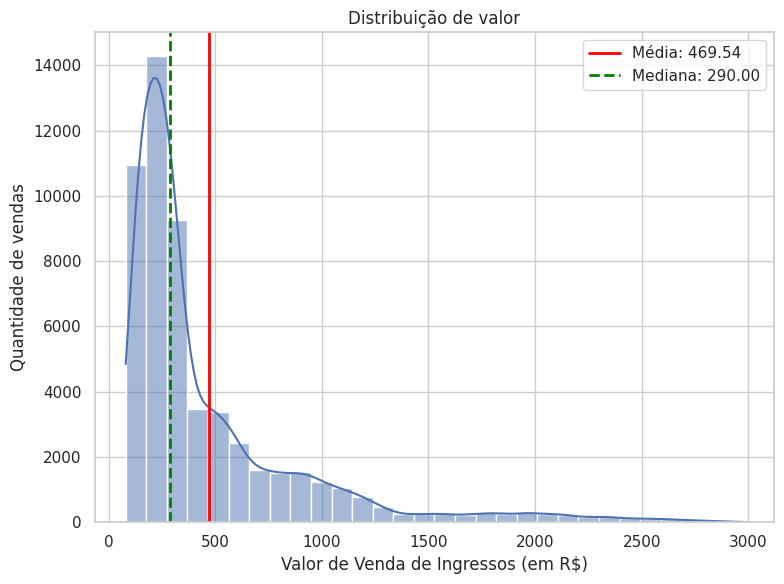

In [ ]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor de Venda de Ingressos (em R$)")
plt.ylabel("Quantidade de vendas")
plt.legend()
plt.tight_layout()
plt.show()

O gráfico acima mostra a frequência e a distribuição do valor de venda de ingressos em reais. A partir dele, é possível comprovar a assimetria à direita: as colunas mais altas se concentram na faixa entre 0 e 500 reais, diminuindo cada vez mais conforme o valor de venda aumenta. Além disso, a média (linha vermelha) é maior que a mediana (linha tracejada verde), reforçando a ideia de que há outliers distorcendo o valor da média para cima.

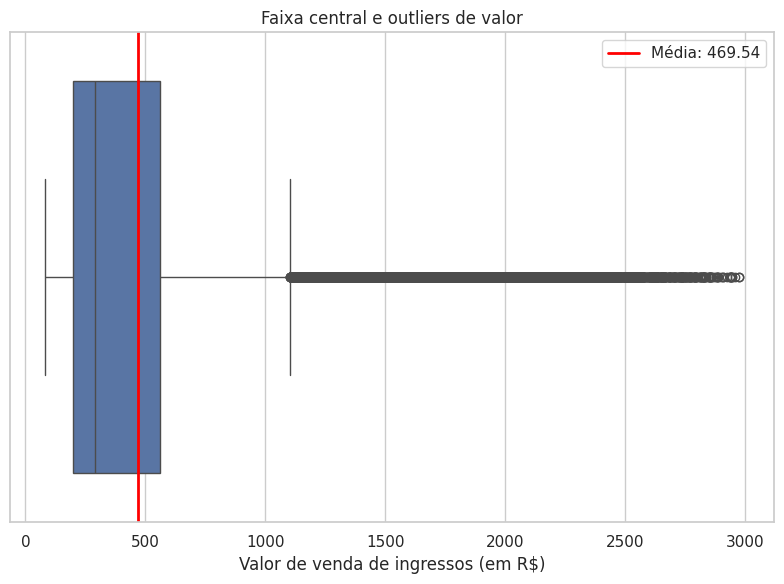

In [ ]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Valor de venda de ingressos (em R$)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O gráfico acima ilustra visualmente a existência de um grande número de outliers: os pontos pretos são tantos que acabam formando uma linha grossa preta. Porém, eles representam valores individuais que estão acima do limite superior de 1104.52.